In [4]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Création du dossier d'export d'images
os.makedirs("figures", exist_ok=True)

# Chargement des deux jeux de données
titanic = pd.read_csv("../exercice-08/data/titanic_propre.csv")
taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])
taxis["date"] = taxis["pickup"].dt.date

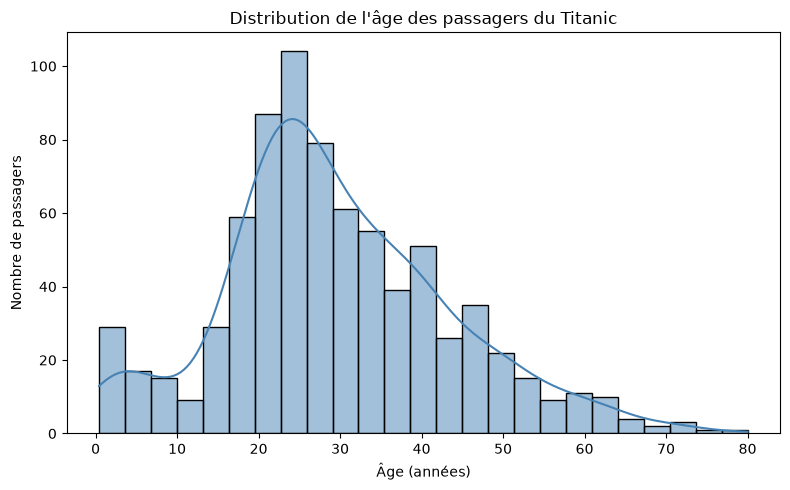

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(titanic["age"], kde=True, bins=25, color="steelblue")
plt.title("Distribution de l'âge des passagers du Titanic")
plt.xlabel("Âge (années)")
plt.ylabel("Nombre de passagers")
plt.tight_layout()
plt.savefig("figures/01_distribution_age.png")
plt.show()

La majorité des passagers avait entre 20 et 35 ans, avec un second pic notable chez les jeunes enfants (0-5 ans).


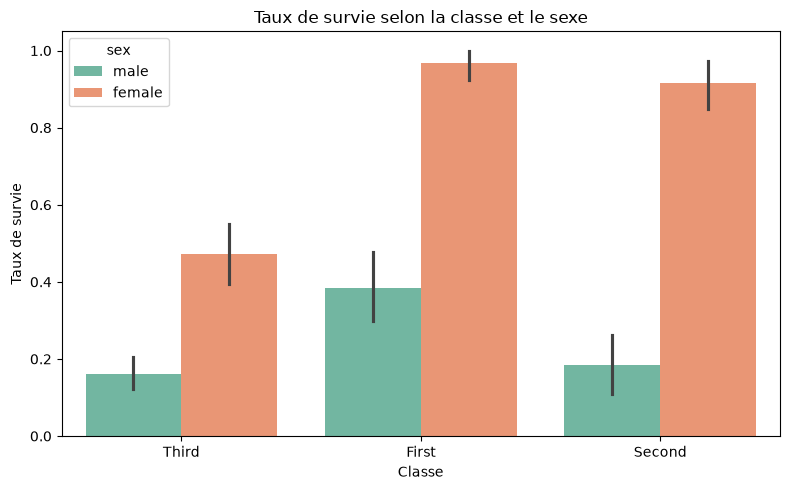

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(data=titanic, x="class", y="survived", hue="sex", palette="Set2")
plt.title("Taux de survie selon la classe et le sexe")
plt.xlabel("Classe")
plt.ylabel("Taux de survie")
plt.tight_layout()
plt.savefig("figures/02_survie_classe_sexe.png")
plt.show()

Les femmes de 1re et 2e classe affichent les taux de survie les plus élevés (supérieurs à 90 %), tandis que les hommes de 2e et 3e classe ont le taux de survie le plus bas (inférieur à 20 %).

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_29116\4204574173.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=titanic, x="class", y="fare", palette="Pastel1")


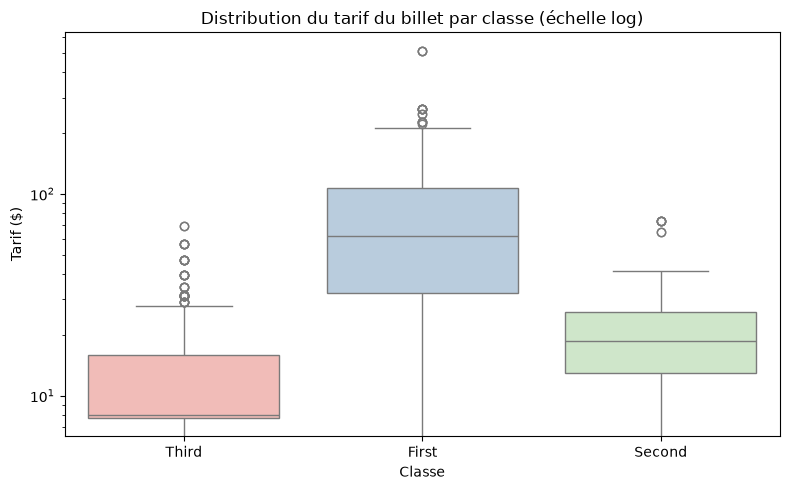

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=titanic, x="class", y="fare", palette="Pastel1")
plt.yscale("log")  # Échelle logarithmique pour rendre les écarts lisibles
plt.title("Distribution du tarif du billet par classe (échelle log)")
plt.xlabel("Classe")
plt.ylabel("Tarif ($)")
plt.tight_layout()
plt.savefig("figures/03_prix_selon_classe.png")
plt.show()

Le tarif médian augmente nettement avec le rang de la classe, la 1re classe concentrant une grande dispersion et des valeurs extrêmes très élevées.

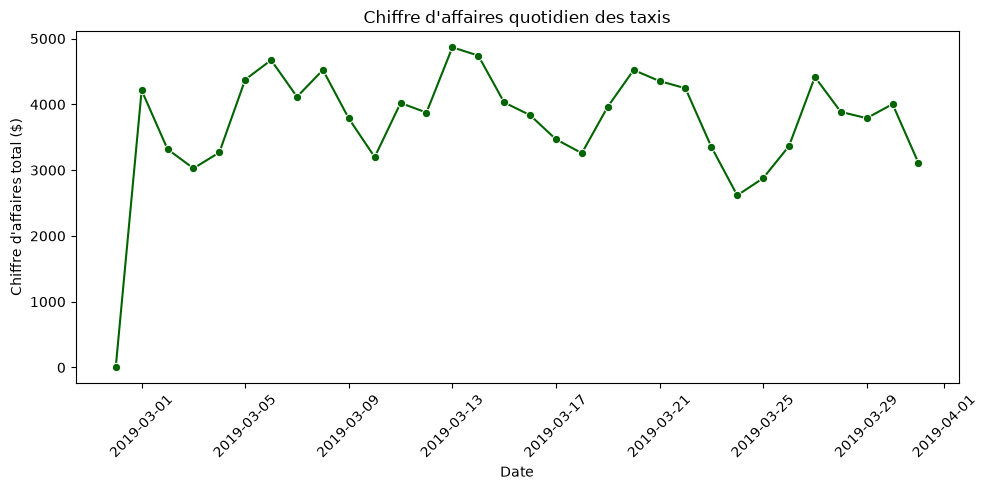

In [8]:
ca_journalier = (
    taxis.groupby("date")["total"].sum().reset_index()
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=ca_journalier, x="date", y="total", marker="o", color="darkgreen"
)
plt.title("Chiffre d'affaires quotidien des taxis")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires total ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/04_ca_journalier_taxis.png")
plt.show()

L'activité présente une périodicité hebdomadaire régulière, marquée par des pics de recettes systématiques les week-ends.

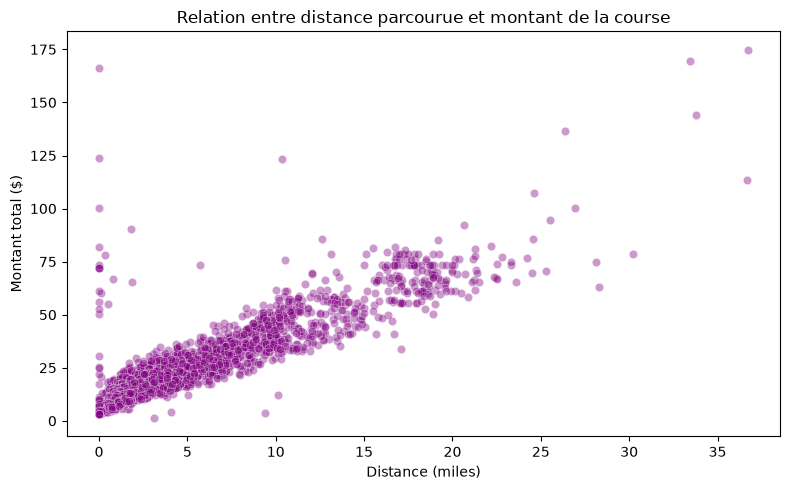

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=taxis, x="distance", y="total", alpha=0.4, color="purple"
)
plt.title("Relation entre distance parcourue et montant de la course")
plt.xlabel("Distance (miles)")
plt.ylabel("Montant total ($)")
plt.tight_layout()
plt.savefig("figures/05_distance_vs_prix.png")
plt.show()

Il existe une forte corrélation linéaire positive : plus la distance augmente, plus le montant s'élève, avec quelques tarifs fixes spécifiques visibles (trajets aéroportuaires forfaitaires).